In [2]:
%pip install pymc arviz

   ---------------------------------------- 0.0/608.3 kB ? eta -:--:--
   ---------------------------------------- 0.0/608.3 kB ? eta -:--:--
   ---------------------------------------- 0.0/608.3 kB ? eta -:--:--
   ---------------------------------------- 0.0/608.3 kB ? eta -:--:--
   ---------------------------------------- 0.0/608.3 kB ? eta -:--:--
   ---------------------------------------- 0.0/608.3 kB ? eta -:--:--
   ---------------------------------------- 0.0/608.3 kB ? eta -:--:--
   ---------------------------------------- 0.0/608.3 kB ? eta -:--:--
   ---------------------------------------- 0.0/608.3 kB ? eta -:--:--
   ---------------------------------------- 0.0/608.3 kB ? eta -:--:--
   ----------------- ---------------------- 262.1/608.3 kB ? eta -:--:--
   ----------------- ---------------------- 262.1/608.3 kB ? eta -:--:--
   ----------------- ---------------------- 262.1/608.3 kB ? eta -:--:--
   ----------------- ---------------------- 262.1/608.3 kB ? eta -:--:-

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import pytensor.tensor as pt


R = 2.0       # Радиус детектора, м
N_pmts = 40   # Количество ФЭУ
r = 0.1       # Радиус ФЭУ, м
a = 0.5       # Квантовая эффективность
Y = 10000     # Выход фотонов на МэВ
E = 1.0       # Энергия события, МэВ
L = 8.0       # Длина затухания, м



In [12]:
indices = np.arange(0, N_pmts, dtype=float) + 0.5
phi = np.arccos(1 - 2 * indices / N_pmts)
theta = np.pi * (1 + 5**0.5) * indices

x = np.cos(theta) * np.sin(phi) * R
y = np.sin(theta) * np.sin(phi) * R
z = np.cos(phi) * R


pmt_positions = np.column_stack([x, y, z])
pmt_normals = pmt_positions / R

In [14]:
with pm.Model() as detector_model:
    source_pos = pt.as_tensor_variable([0.0, 0.0, 0.0])
    vec_to_pmt = pt.as_tensor_variable(pmt_positions) - source_pos
    distances = pt.sqrt(pt.sum(vec_to_pmt**2, axis=1))

    cos_theta = pt.abs(pt.sum(pmt_normals * vec_to_pmt, axis=1)) / distances
    area = np.pi * r**2
    solid_angle = (area * cos_theta) / (distances**2)
    fraction = solid_angle / (4 * np.pi)
    
    survival_prob = pt.exp(-distances / L)
    fraction_att = fraction * survival_prob
    

    total_photons = Y * E
    expected_pe = a * (total_photons * fraction_att)
    
    pe = pm.Poisson('pe', mu=expected_pe, shape=N_pmts)
    total_charge = pm.Deterministic('total_charge', pt.sum(pe))



In [17]:

charges_pymc = pm.draw(detector_model['total_charge'], draws=2000)

print("Получено событий:", len(charges_pymc))



Получено событий: 2000


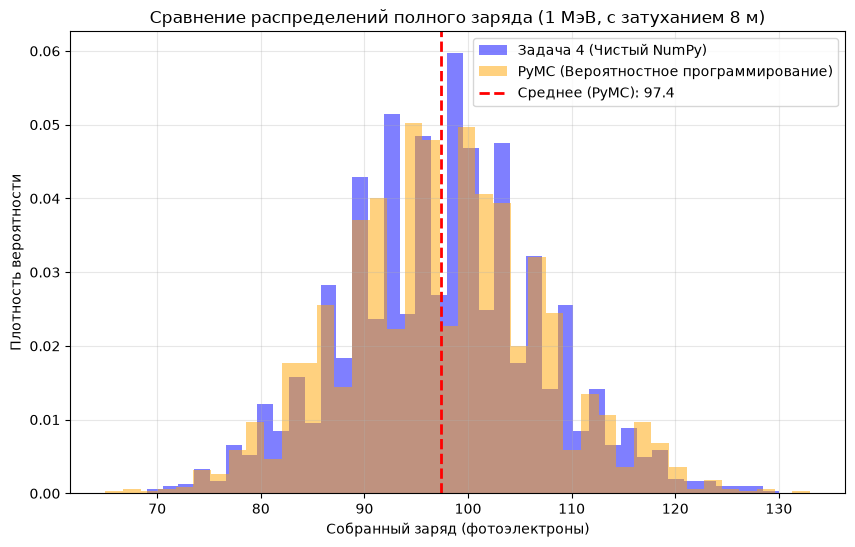

Среднее значение (NumPy): 97.5
Среднее значение (PyMC):  97.4
Стандартное отклонение (PyMC): 9.7


In [18]:
import matplotlib.pyplot as plt
import numpy as np

expected_pe_np = expected_pe.eval()
charges_numpy = np.random.poisson(expected_pe_np, size=(2000, N_pmts)).sum(axis=1)


plt.figure(figsize=(10, 6))


plt.hist(charges_numpy, bins=40, alpha=0.5, label='Задача 4 (NumPy)', color='blue', density=True)
plt.hist(charges_pymc, bins=40, alpha=0.5, label='PyMC', color='orange', density=True)

plt.title('Сравнение распределений полного заряда (1 МэВ, с затуханием 8 м)')
plt.xlabel('Собранный заряд ')
plt.ylabel('Плотность вероятности')
plt.axvline(np.mean(charges_pymc), color='red', linestyle='dashed', linewidth=2, label=f'Среднее (PyMC): {np.mean(charges_pymc):.1f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Среднее значение (NumPy): {np.mean(charges_numpy):.1f}")
print(f"Среднее значение (PyMC):  {np.mean(charges_pymc):.1f}")
print(f"Стандартное отклонение (PyMC): {np.std(charges_pymc):.1f}")